In [295]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor

In [296]:
import pandas as pd


# Load the sales dataset
df_sales = pd.read_csv("retail_sales_ml_apl.csv")

In [297]:
# Check Shape
print("Sales shape:", df_sales.shape)

Sales shape: (125751, 17)


In [298]:
df_sales.head(3)

,Transaction Date,Sales Type,Is Return,Reason of Return,Supplier,Product No,Product Description,Product Division,Product Category,Product Subcategory,Product Segment,Store,Sales Channel,Qty Sold,Sales Amount,Cogs,Number of Transactions
0,2025-09-01,Full Price,0,NaN,Vendor 0169,PROD-139867,PROD-100449 SEG-500065 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-500065 Scholar Footwear Trailblazer Equili...,STR-1006,Channel Alpha,1.0,115.00,52.31,1
1,2025-09-07,Full Price,0,NaN,Vendor 0166,PROD-100449,PROD-100825 SEG-500112 Heritage Footwear Fligh...,Femme Footwear,Femme Footwear Flight Classic,Femme Footwear Flight Classic Varied,SEG-500112 Heritage Footwear Flight Classic Ze...,STR-1198,Channel Alpha,1.0,115.00,58.47,1
2,2025-08-06,Promo,0,NaN,Vendor 0169,PROD-153623,PROD-148813 SEG-511388 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-511388 Scholar Footwear Trailblazer Equili...,STR-1157,Channel Alpha,1.0,79.99,43.76,1


In [299]:
# Make a copy of the sales data
df_sales_clean = df_sales.copy()

In [300]:
df_sales_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125751 entries, 0 to 125750
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Transaction Date        125751 non-null  object 
 1   Sales Type              125751 non-null  object 
 2   Is Return               125751 non-null  int64  
 3   Reason of Return        0 non-null       float64
 4   Supplier                125751 non-null  object 
 5   Product No              125751 non-null  object 
 6   Product Description     125751 non-null  object 
 7   Product Division        125751 non-null  object 
 8   Product Category        125751 non-null  object 
 9   Product Subcategory     125751 non-null  object 
 10  Product Segment         125751 non-null  object 
 11  Store                   125751 non-null  object 
 12  Sales Channel           125751 non-null  object 
 13  Qty Sold                125751 non-null  float64
 14  Sales Amount        

In [301]:
# convert to dt
df_sales_clean["Transaction Date"] = pd.to_datetime(df_sales_clean["Transaction Date"],
    errors="coerce"
)

In [302]:
# Check dt
df_sales_clean["Transaction Date"].dtypes

dtype('<M8[ns]')

In [303]:
# Check for missing value and duplicates
print("Missing values:")
display(df_sales_clean.isnull().sum())

print("Exact duplicate rows:", df_sales_clean.duplicated().sum())

Missing values:


Transaction Date               0
Sales Type                     0
Is Return                      0
Reason of Return          125751
Supplier                       0
Product No                     0
Product Description            0
Product Division               0
Product Category               0
Product Subcategory            0
Product Segment                0
Store                          0
Sales Channel                  0
Qty Sold                       0
Sales Amount                   0
Cogs                           0
Number of Transactions         0
dtype: int64

Exact duplicate rows: 0


In [304]:
# Drop empty column 
df_sales_clean= df_sales_clean.drop(columns='Reason of Return')

In [305]:
df_sales_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125751 entries, 0 to 125750
Data columns (total 16 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   Transaction Date        125751 non-null  datetime64[ns]
 1   Sales Type              125751 non-null  object        
 2   Is Return               125751 non-null  int64         
 3   Supplier                125751 non-null  object        
 4   Product No              125751 non-null  object        
 5   Product Description     125751 non-null  object        
 6   Product Division        125751 non-null  object        
 7   Product Category        125751 non-null  object        
 8   Product Subcategory     125751 non-null  object        
 9   Product Segment         125751 non-null  object        
 10  Store                   125751 non-null  object        
 11  Sales Channel           125751 non-null  object        
 12  Qty Sold                125751

In [306]:
print("Total sales records:", len(df_sales_clean))
print("Date range:")
print(df_sales_clean["Transaction Date"].min())
print(df_sales_clean["Transaction Date"].max())

print("\nUnique products:", df_sales_clean["Product No"].nunique())
print("Unique stores:", df_sales_clean["Store"].nunique())

print("\nTotal quantity sold:", df_sales_clean["Qty Sold"].sum())
print("Total sales amount:", df_sales_clean["Sales Amount"].sum())
print("Total COGS:", df_sales_clean["Cogs"].sum())

Total sales records: 125751
Date range:
2025-06-01 00:00:00
2026-04-24 00:00:00

Unique products: 2326
Unique stores: 40

Total quantity sold: 116995.0
Total sales amount: 10482110.250000004
Total COGS: 5847751.0999


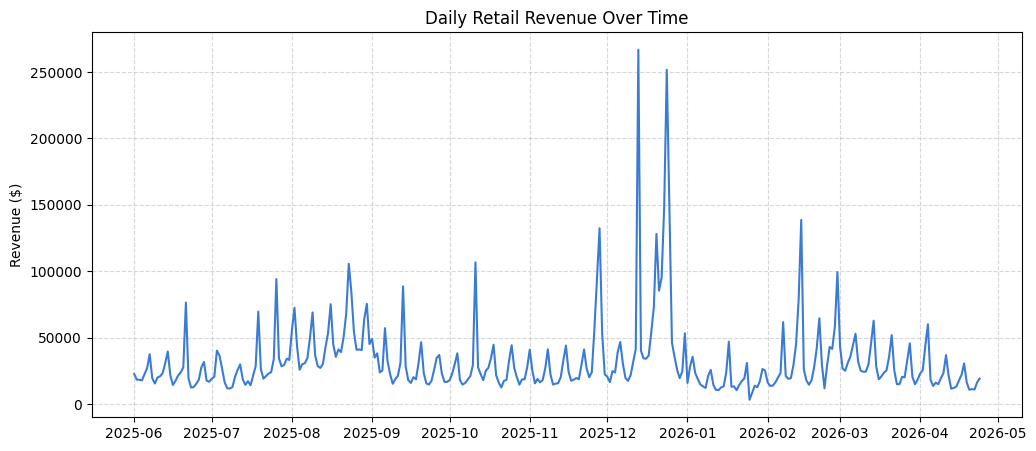

In [307]:
daily_sales = df_sales_clean.groupby("Transaction Date")["Sales Amount"].sum()

plt.figure(figsize=(12, 5))
plt.plot(daily_sales.index, daily_sales.values, color="#3A7BD5", linewidth=1.5)
plt.title("Daily Retail Revenue Over Time")
plt.ylabel("Revenue ($)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [308]:
daily_sales = (
    df_sales_clean.groupby('Transaction Date')['Sales Amount']
    .sum()
    .reset_index()
)

daily_sales = daily_sales.sort_values('Transaction Date').reset_index(drop=True)

In [356]:
total_revenue = df_sales_clean['Sales Amount'].sum()

print(f"Total Revenue: ${total_revenue:,.2f}")

Total Revenue: $10,482,110.25


In [309]:
daily_sales

,Transaction Date,Sales Amount
0,2025-06-01,22565.33
1,2025-06-02,18327.55
2,2025-06-03,18222.65
3,2025-06-04,17763.89
4,2025-06-05,22450.25
...,...,...
321,2026-04-20,10706.34
322,2026-04-21,11216.64
323,2026-04-22,10858.80
324,2026-04-23,16101.66


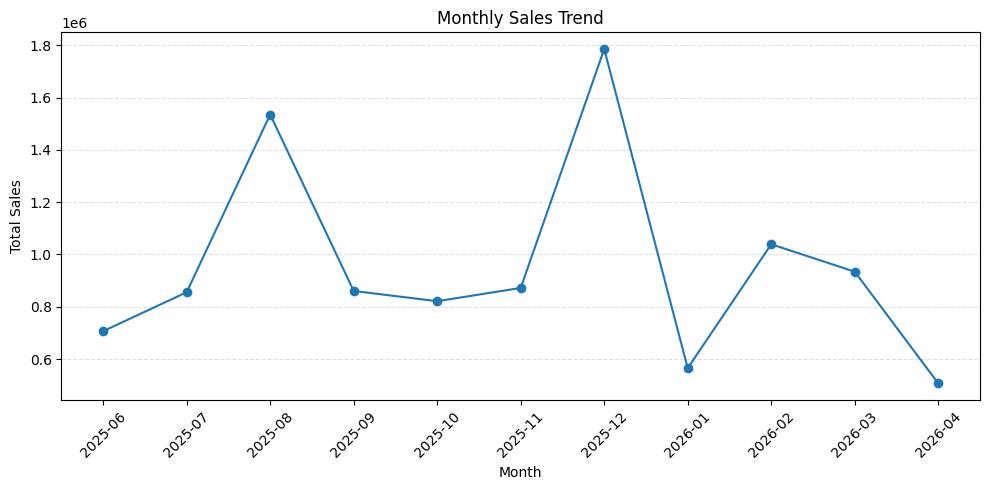

In [310]:
# Monthly Sales Trend
monthly_sales = (
    df_sales_clean
    .groupby(df_sales_clean["Transaction Date"].dt.to_period("M"))["Sales Amount"]
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [311]:
monthly_sales

Transaction Date
2025-06     706683.44
2025-07     855571.55
2025-08    1535117.21
2025-09     860457.23
2025-10     821266.08
2025-11     871946.34
2025-12    1785534.95
2026-01     565272.83
2026-02    1038967.86
2026-03     934194.48
2026-04     507098.28
Name: Sales Amount, dtype: float64

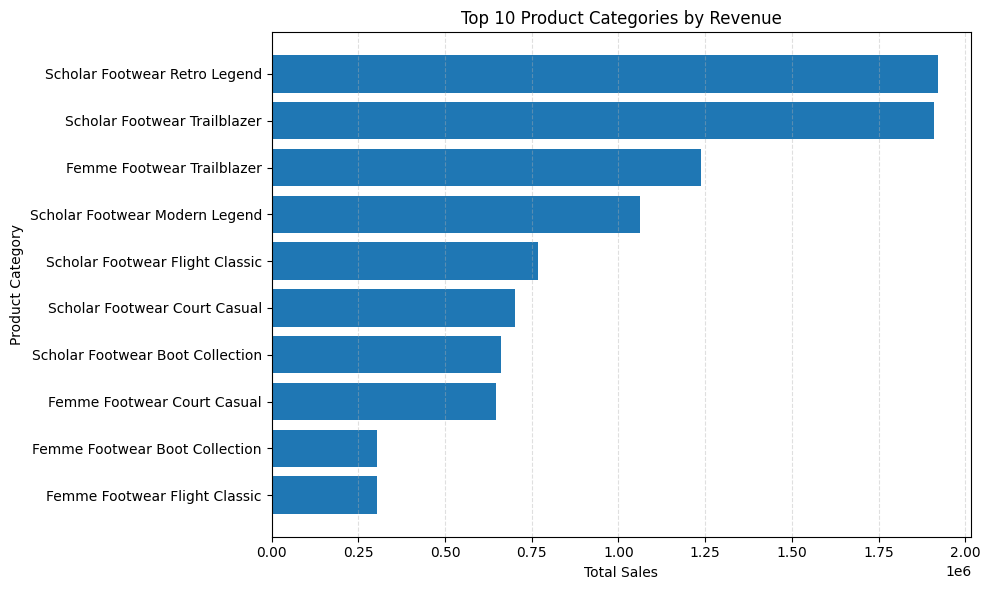

In [312]:
# Top 10 Product Categories by Revenue
category_sales = (
    df_sales_clean
    .groupby("Product Category")["Sales Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
plt.barh(category_sales.index, category_sales.values)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Total Sales")
plt.ylabel("Product Category")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [313]:
category_sales

Product Category
Femme Footwear Flight Classic        303495.26
Femme Footwear Boot Collection       304630.62
Femme Footwear Court Casual          647820.37
Scholar Footwear Boot Collection     660152.85
Scholar Footwear Court Casual        702385.90
Scholar Footwear Flight Classic      767298.33
Scholar Footwear Modern Legend      1062646.92
Femme Footwear Trailblazer          1238790.65
Scholar Footwear Trailblazer        1909759.99
Scholar Footwear Retro Legend       1920958.56
Name: Sales Amount, dtype: float64

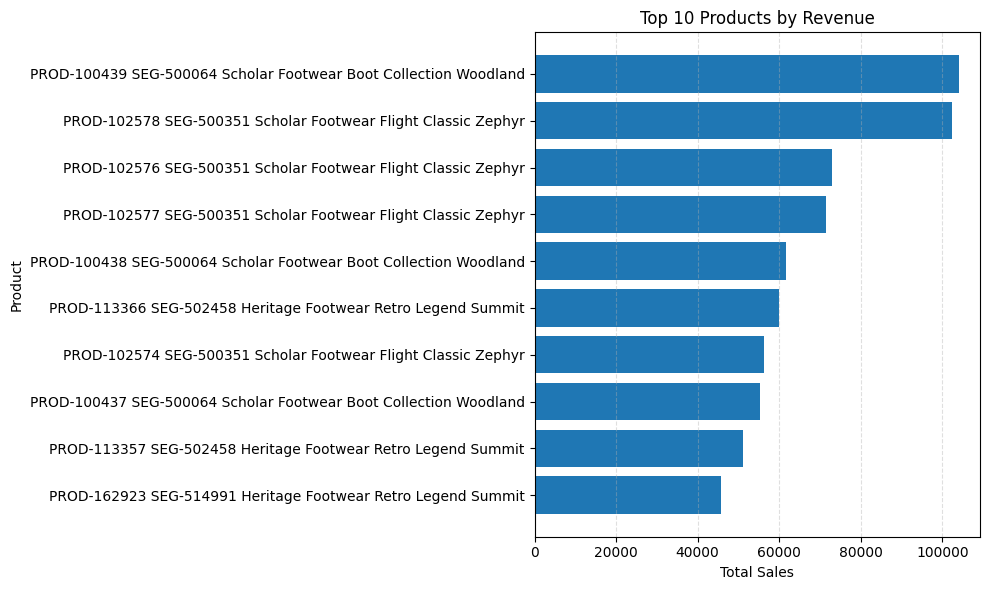

In [314]:
# Top 10 Products by Revenue
top_products = (
    df_sales_clean
    .groupby("Product Description")["Sales Amount"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
plt.barh(top_products.index, top_products.values)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [315]:
top_products

Product Description
PROD-162923 SEG-514991 Heritage Footwear Retro Legend Summit         45672.00
PROD-113357 SEG-502458 Heritage Footwear Retro Legend Summit         51110.00
PROD-100437 SEG-500064 Scholar Footwear Boot Collection Woodland     55251.90
PROD-102574 SEG-500351 Scholar Footwear Flight Classic Zephyr        56361.50
PROD-113366 SEG-502458 Heritage Footwear Retro Legend Summit         60040.00
PROD-100438 SEG-500064 Scholar Footwear Boot Collection Woodland     61705.00
PROD-102577 SEG-500351 Scholar Footwear Flight Classic Zephyr        71496.48
PROD-102576 SEG-500351 Scholar Footwear Flight Classic Zephyr        72822.50
PROD-102578 SEG-500351 Scholar Footwear Flight Classic Zephyr       102481.99
PROD-100439 SEG-500064 Scholar Footwear Boot Collection Woodland    104027.50
Name: Sales Amount, dtype: float64

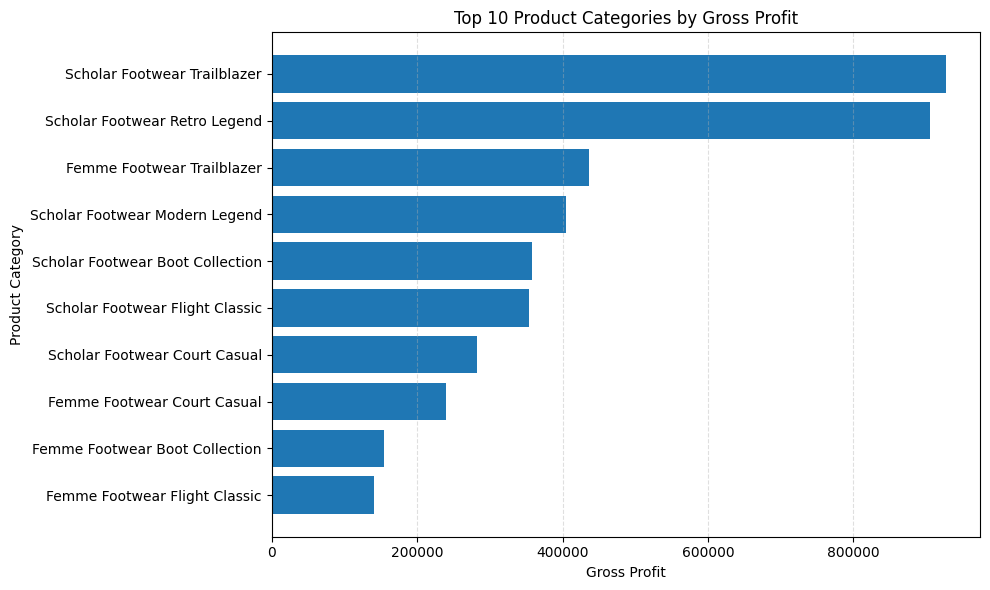

In [316]:
# Top 10 Product Categories by Gross Profit
category_profit = (
    df_sales_clean
    .groupby("Product Category")
    .agg(
        Revenue=("Sales Amount", "sum"),
        COGS=("Cogs", "sum")
    )
)

category_profit["Gross Profit"] = (
    category_profit["Revenue"] - category_profit["COGS"]
)

top_profit = (
    category_profit["Gross Profit"]
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
plt.barh(top_profit.index, top_profit.values)

plt.title("Top 10 Product Categories by Gross Profit")
plt.xlabel("Gross Profit")
plt.ylabel("Product Category")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [317]:
category_profit

,Revenue,COGS,Gross Profit
Product Category,,,
Femme Footwear Boot Collection,304630.62,1.501271e+05,154503.4900
Femme Footwear Court Casual,647820.37,4.077026e+05,240117.8001
Femme Footwear Flight Classic,303495.26,1.626066e+05,140888.6700
Femme Footwear Modern Legend,39802.63,2.381609e+04,15986.5400
Femme Footwear Retro Legend,177667.32,9.251090e+04,85156.4200
Femme Footwear Trailblazer,1238790.65,8.021016e+05,436689.0400
Junior Apparel Cozy Pullovers,91458.26,5.589770e+04,35560.5600
Junior Apparel Cozy Trousers,89165.69,5.319890e+04,35966.7900
Junior Apparel Crew Tees,86652.57,4.563855e+04,41014.0200


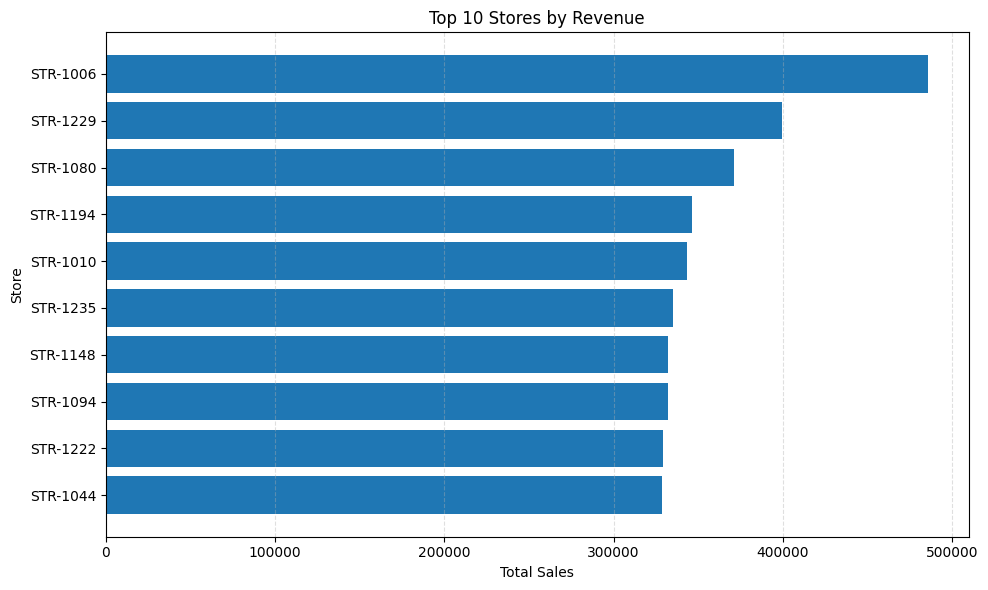

In [318]:
# Top 10 Stores by Revenue
store_sales = (
    df_sales_clean
    .groupby("Store")["Sales Amount"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
plt.barh(store_sales.index, store_sales.values)

plt.title("Top 10 Stores by Revenue")
plt.xlabel("Total Sales")
plt.ylabel("Store")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [319]:
store_sales

Store
STR-1044    328466.36
STR-1222    329188.10
STR-1094    332104.96
STR-1148    332396.05
STR-1235    335338.71
STR-1010    343436.84
STR-1194    346391.53
STR-1080    371277.03
STR-1229    399696.48
STR-1006    485561.44
Name: Sales Amount, dtype: float64

In [320]:
monthly_sales

Transaction Date
2025-06     706683.44
2025-07     855571.55
2025-08    1535117.21
2025-09     860457.23
2025-10     821266.08
2025-11     871946.34
2025-12    1785534.95
2026-01     565272.83
2026-02    1038967.86
2026-03     934194.48
2026-04     507098.28
Name: Sales Amount, dtype: float64

In [321]:
# Check what Product sold more in december because it had the most monthly sales
december_sales = df_sales_clean[
    df_sales_clean["Transaction Date"].dt.month == 12
]

top_december_categories = (
    december_sales
    .groupby("Product Category")["Sales Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_december_categories

Product Category
Scholar Footwear Retro Legend       330845.99
Scholar Footwear Trailblazer        260957.02
Scholar Footwear Boot Collection    219918.73
Scholar Footwear Modern Legend      197125.03
Femme Footwear Trailblazer          189127.87
Femme Footwear Boot Collection      134575.58
Scholar Footwear Court Casual       108739.38
Scholar Footwear Flight Classic      96799.48
Femme Footwear Court Casual          84345.03
Femme Footwear Flight Classic        25145.52
Name: Sales Amount, dtype: float64

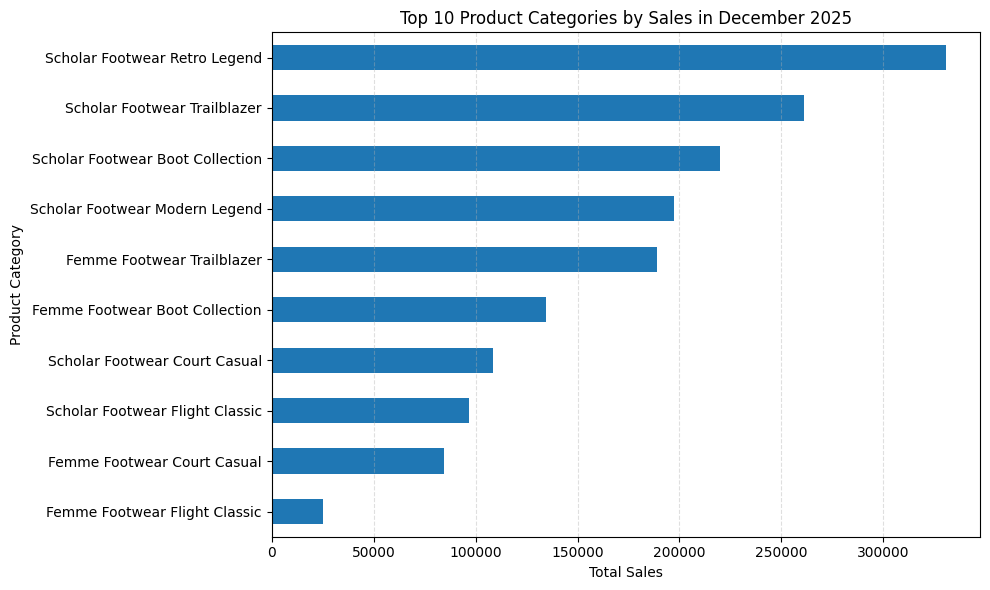

In [322]:
top_december_categories.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Product Categories by Sales in December 2025")
plt.xlabel("Total Sales")
plt.ylabel("Product Category")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [323]:
top_december_categories

Product Category
Scholar Footwear Retro Legend       330845.99
Scholar Footwear Trailblazer        260957.02
Scholar Footwear Boot Collection    219918.73
Scholar Footwear Modern Legend      197125.03
Femme Footwear Trailblazer          189127.87
Femme Footwear Boot Collection      134575.58
Scholar Footwear Court Casual       108739.38
Scholar Footwear Flight Classic      96799.48
Femme Footwear Court Casual          84345.03
Femme Footwear Flight Classic        25145.52
Name: Sales Amount, dtype: float64

In [324]:
df_sales_clean['Is Return'].value_counts()

Is Return
0    118260
1      7491
Name: count, dtype: int64

In [325]:
return_analysis = (
    df_sales_clean
    .groupby("Is Return")
    .agg(
        Records=("Is Return", "size"),
        Quantity=("Qty Sold", "sum"),
        Sales_Amount=("Sales Amount", "sum"),
        COGS=("Cogs", "sum")
    )
)

return_analysis["Gross Profit"] = (
    return_analysis["Sales_Amount"] - return_analysis["COGS"]
)

return_analysis

,Records,Quantity,Sales_Amount,COGS,Gross Profit
Is Return,,,,,
0,118260,124542.0,11215681.26,6.255527e+06,4.960154e+06
1,7491,-7547.0,-733571.01,-4.077757e+05,-3.257953e+05


In [326]:
total_sales = df_sales_clean["Sales Amount"].sum()
total_cogs = df_sales_clean["Cogs"].sum()
gross_profit = total_sales - total_cogs

print(f"Net Sales: {total_sales:,.2f}")
print(f"Net COGS: {total_cogs:,.2f}")
print(f"Gross Profit: {gross_profit:,.2f}")
print(f"Gross Profit Margin: {gross_profit / total_sales * 100:.2f}%")

Net Sales: 10,482,110.25
Net COGS: 5,847,751.10
Gross Profit: 4,634,359.15
Gross Profit Margin: 44.21%


In [327]:
store_performance = (
    df_sales_clean
    .groupby("Store")
    .agg(
        Net_Sales=("Sales Amount", "sum"),
        Net_COGS=("Cogs", "sum")
    )
)

store_performance["Gross Profit"] = (
    store_performance["Net_Sales"]
    - store_performance["Net_COGS"]
)

store_performance["Gross Profit Margin (%)"] = (
    store_performance["Gross Profit"]
    / store_performance["Net_Sales"]
    * 100
)

top_stores = store_performance.nlargest(10, "Gross Profit")

top_stores

,Net_Sales,Net_COGS,Gross Profit,Gross Profit Margin (%)
Store,,,,
STR-1006,485561.44,259786.2999,225775.1401,46.497749
STR-1229,399696.48,222383.6100,177312.8700,44.361879
STR-1080,371277.03,199581.9400,171695.0900,46.244469
STR-1194,346391.53,192287.6600,154103.8700,44.488348
STR-1010,343436.84,192328.1700,151108.6700,43.998969
STR-1222,329188.10,178765.3300,150422.7700,45.695081
STR-1044,328466.36,179081.0900,149385.2700,45.479625
STR-1235,335338.71,186237.1100,149101.6000,44.462985
STR-1075,327931.80,180209.4100,147722.3900,45.046680


In [328]:
store_performance

,Net_Sales,Net_COGS,Gross Profit,Gross Profit Margin (%)
Store,,,,
STR-1006,485561.44,259786.2999,225775.1401,46.497749
STR-1010,343436.84,192328.1700,151108.6700,43.998969
STR-1026,243589.79,134102.8000,109486.9900,44.947282
STR-1038,258637.20,144831.3000,113805.9000,44.002139
STR-1044,328466.36,179081.0900,149385.2700,45.479625
STR-1074,241739.21,133658.6000,108080.6100,44.709590
STR-1075,327931.80,180209.4100,147722.3900,45.046680
STR-1080,371277.03,199581.9400,171695.0900,46.244469
STR-1082,217612.17,121326.3600,96285.8100,44.246519


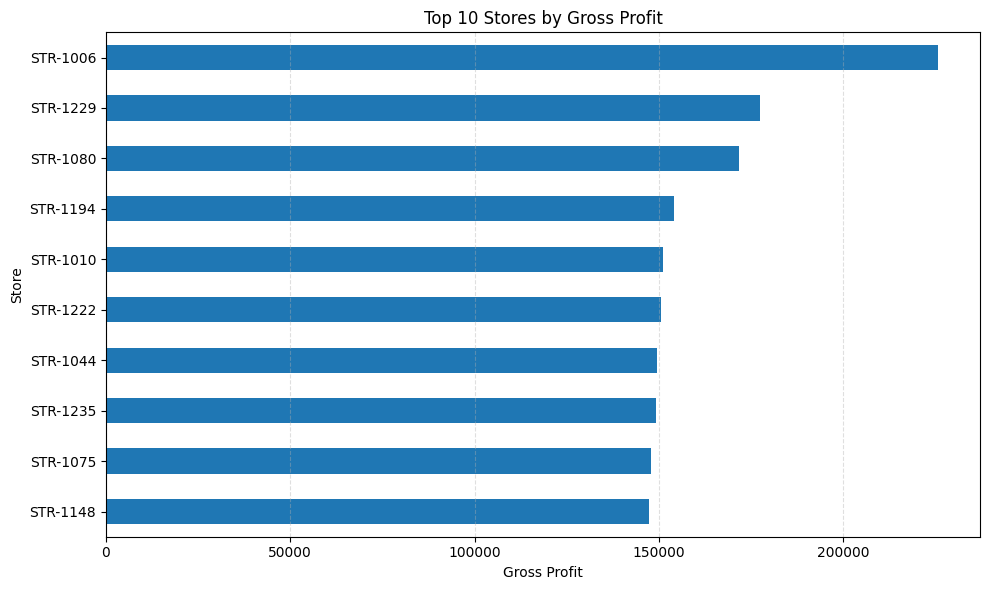

In [329]:
top_stores["Gross Profit"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Stores by Gross Profit")
plt.xlabel("Gross Profit")
plt.ylabel("Store")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [330]:
top_stores

,Net_Sales,Net_COGS,Gross Profit,Gross Profit Margin (%)
Store,,,,
STR-1006,485561.44,259786.2999,225775.1401,46.497749
STR-1229,399696.48,222383.6100,177312.8700,44.361879
STR-1080,371277.03,199581.9400,171695.0900,46.244469
STR-1194,346391.53,192287.6600,154103.8700,44.488348
STR-1010,343436.84,192328.1700,151108.6700,43.998969
STR-1222,329188.10,178765.3300,150422.7700,45.695081
STR-1044,328466.36,179081.0900,149385.2700,45.479625
STR-1235,335338.71,186237.1100,149101.6000,44.462985
STR-1075,327931.80,180209.4100,147722.3900,45.046680


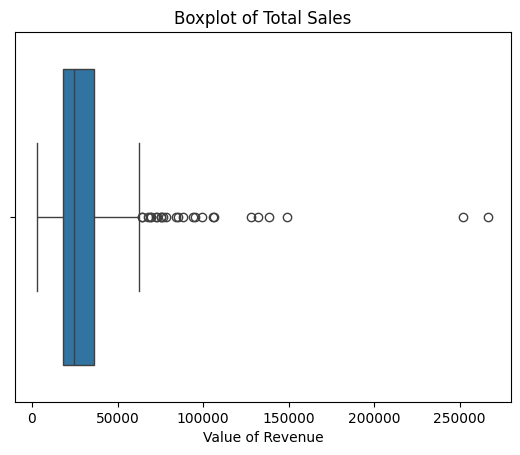

In [331]:
import seaborn as sns 
sns.boxplot(x=daily_sales['Sales Amount'])
plt.title('Boxplot of Total Sales')
plt.xlabel('Value of Revenue')
plt.show()

In [332]:
# Creating Lag features 
daily_sales['lag_1d'] = daily_sales['Sales Amount'].shift(1)
daily_sales['lag_7d'] = daily_sales['Sales Amount'].shift(7)
daily_sales["lag_14d"] = daily_sales["Sales Amount"].shift(14)
daily_sales["lag_30d"] = daily_sales["Sales Amount"].shift(30)

In [333]:
# Creating Rolling features
# Rolling features on Log Target (shifted by 1 to prevent data leakage)
daily_sales['rolling_mean_7d'] = daily_sales['Sales Amount'].shift(1).rolling(7).mean()
daily_sales["rolling_mean_30d"] = daily_sales["Sales Amount"].shift(1).rolling(30).mean()

In [334]:
daily_sales = daily_sales.dropna().reset_index(drop=True)

In [335]:
# Check head
daily_sales.head(5)

,Transaction Date,Sales Amount,lag_1d,lag_7d,lag_14d,lag_30d,rolling_mean_7d,rolling_mean_30d
0,2025-07-01,19023.62,16767.31,12712.14,17517.36,22565.33,19989.022857,23556.114667
1,2025-07-02,20531.46,19023.62,15150.61,21426.54,18327.55,20890.662857,23438.057667
2,2025-07-03,40187.76,20531.46,18316.60,23829.46,18222.65,21659.355714,23511.521333
3,2025-07-04,36447.92,40187.76,27724.35,27492.59,17763.89,24783.807143,24243.691667
4,2025-07-05,26669.50,36447.92,31612.86,76380.77,22450.25,26030.031429,24866.492667


In [336]:
daily_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction Date  296 non-null    datetime64[ns]
 1   Sales Amount      296 non-null    float64       
 2   lag_1d            296 non-null    float64       
 3   lag_7d            296 non-null    float64       
 4   lag_14d           296 non-null    float64       
 5   lag_30d           296 non-null    float64       
 6   rolling_mean_7d   296 non-null    float64       
 7   rolling_mean_30d  296 non-null    float64       
dtypes: datetime64[ns](1), float64(7)
memory usage: 18.6 KB


In [337]:
daily_sales["Month"] = daily_sales["Transaction Date"].dt.month
daily_sales["Day"] = daily_sales["Transaction Date"].dt.day
daily_sales["Year"] = daily_sales["Transaction Date"].dt.year

# Flag Q4 High-Seasonality Months (Oct, Nov, Dec)
daily_sales["is_q4"] = daily_sales["Month"].isin([10, 11, 12]).astype(int)

# Flag Paydays / End-of-Month Spikes
daily_sales["is_month_start"] = (daily_sales["Day"] <= 3).astype(int)
daily_sales["is_month_end"] = (daily_sales["Day"] >= 28).astype(int)

In [338]:
# Create a DayofWeek column and Weekend column
daily_sales['DayOfWeek'] = daily_sales['Transaction Date'].dt.dayofweek
daily_sales['IsWeekend'] = (daily_sales['DayOfWeek'] >= 5).astype(int)

In [339]:
daily_sales['time_index'] = range(len(daily_sales))

In [340]:
daily_sales.columns

Index(['Transaction Date', 'Sales Amount', 'lag_1d', 'lag_7d', 'lag_14d',
       'lag_30d', 'rolling_mean_7d', 'rolling_mean_30d', 'Month', 'Day',
       'Year', 'is_q4', 'is_month_start', 'is_month_end', 'DayOfWeek',
       'IsWeekend', 'time_index'],
      dtype='object')

In [341]:
features = [
    'time_index',
    'Month',
    'Day',
    'DayOfWeek',
    'IsWeekend',
    'is_q4',
    'is_month_start',
    'is_month_end',
    'lag_1d',
    'lag_7d',
    'lag_14d',
    'lag_30d',
    'rolling_mean_7d',
    'rolling_mean_30d'
]
X = daily_sales[features]
y = daily_sales['Sales Amount']

In [342]:
# Find the index position for the 80% 
split_idx = int(len(X) * 0.8)
split_idx

236

In [343]:
# Slice the early dates (0 to 80%) for training
X_train = X.iloc[:split_idx]
y_train = y.iloc[:split_idx]

In [344]:
# Slice the remaining dates (80% to 100%) for testing
X_test = X.iloc[split_idx:]
y_test = y.iloc[split_idx:]

In [345]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(236, 14)
(236,)
(60, 14)
(60,)


In [346]:
# Using Random Forest
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=15, min_samples_leaf=2, min_samples_split=5,
                      n_estimators=300, n_jobs=-1, random_state=42)

In [347]:
rf_pred = rf_model.predict(X_test)

In [348]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest")
print(f"MAE: ${rf_mae:,.2f}")
print(f"RMSE: ${rf_rmse:,.2f}")
print(f"R²: {rf_r2:.4f}")

Random Forest
MAE: $5,996.40
RMSE: $7,722.96
R²: 0.7668


In [349]:
#Using Gradient Boosting
gb_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

gb_model.fit(X_train, y_train)

GradientBoostingRegressor(learning_rate=0.05, max_depth=5, min_samples_leaf=2,
                          min_samples_split=5, n_estimators=300,
                          random_state=42)

In [350]:
gb_pred = gb_model.predict(X_test)

In [351]:
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_r2 = r2_score(y_test, gb_pred)


print("Gradient Boost")
print(f"MAE: ${gb_mae:,.2f}")
print(f"RMSE: ${gb_rmse:,.2f}")
print(f"R²: {gb_r2:.4f}")

Gradient Boost
MAE: $5,542.76
RMSE: $8,156.44
R²: 0.7399


In [352]:
# Using CatBoost
cat_model = CatBoostRegressor(
    iterations=300,
    learning_rate=0.05,
    depth=5,
    random_seed=42,
    verbose=0
)

cat_model.fit(X_train, y_train)

cat_pred = cat_model.predict(X_test)

cat_mae = mean_absolute_error(y_test, cat_pred)
cat_rmse = np.sqrt(mean_squared_error(y_test, cat_pred))
cat_r2 = r2_score(y_test, cat_pred)

print("CatBoost")
print(f"MAE: ${cat_mae:,.2f}")
print(f"RMSE: ${cat_rmse:,.2f}")
print(f"R²: {cat_r2:.4f}")

CatBoost
MAE: $4,324.04
RMSE: $5,872.54
R²: 0.8652


In [353]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': cat_pred
})

comparison['Error'] = (
    comparison['Actual'] - comparison['Predicted']
)

comparison.head(10)

,Actual,Predicted,Error
0,29093.19,19890.218071,9202.971929
1,42905.03,32132.936575,10772.093425
2,41490.08,58672.937916,-17182.857916
3,58124.30,68781.925517,-10657.625517
4,99334.84,84565.492382,14769.347618
5,43675.91,36343.873484,7332.036516
6,26643.85,26603.360845,40.489155
7,25066.02,22921.643925,2144.376075
8,30961.33,27767.662650,3193.667350
9,35594.56,39119.690537,-3525.130537


In [354]:
from sklearn.model_selection import RandomizedSearchCV


base_cat = CatBoostRegressor(random_seed=42, verbose=0)

param_grid = {
    'iterations': [200, 300, 500, 800],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'depth': [4, 5, 6, 8],
    'l2_leaf_reg': [1, 3, 5, 10]
}


random_search = RandomizedSearchCV(
    estimator=base_cat,
    param_distributions=param_grid,
    n_iter=15,
    scoring='r2',
    cv=3,
    random_state=42,  
    n_jobs=-1
)


print("Running hyperparameter tuning for CatBoost...")
random_search.fit(X_train, y_train)


best_cat_model = random_search.best_estimator_

print("\nBest Hyperparameters Found:")
for param, value in random_search.best_params_.items():
    print(f"  {param}: {value}")

tuned_pred = best_cat_model.predict(X_test)
tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

print("\nTuned CatBoost Performance:")
print(f"MAE: ${tuned_mae:,.2f}")
print(f"RMSE: ${tuned_rmse:,.2f}")
print(f"R²: {tuned_r2:.4f}")

Running hyperparameter tuning for CatBoost...

Best Hyperparameters Found:
  learning_rate: 0.03
  l2_leaf_reg: 5
  iterations: 200
  depth: 4

Tuned CatBoost Performance:
MAE: $5,310.03
RMSE: $6,800.88
R²: 0.8192


In [355]:
import joblib
model_artifacts = {
    'model': cat_model,
    'features': features
}

joblib.dump(model_artifacts, 'Business Sales.joblib')

['Business Sales.joblib']